# Lab 3: Clustering Analysis Using K-Means and K-Medoids Algorithms

**Corey Hyde**  
**Student ID:** 003044072  
**Course:** MSCS-634-A01 — Advanced Big Data and Data Mining  
**Assignment:** Lab 3

## Objective
Compare K-Means and K-Medoids clustering on the Wine dataset using three clusters. I will standardize the chemical measurements, compute Silhouette Scores and Adjusted Rand Indices (ARI), and use PCA to display both clustering results in two dimensions.

**Important distinction:** Wine class labels are included only for data exploration and calculating ARI. Neither clustering algorithm uses those labels during fitting.

## 1. Load and explore the dataset

The Wine dataset contains 178 samples, 13 numerical chemical measurements, and three known wine classes. The chemical features are measured on different scales, so I will standardize them before calculating distances.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances

RANDOM_STATE = 42
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(exist_ok=True)

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="actual_class")

print(f"Number of rows: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Missing values: {X.isna().sum().sum()}")
display(X.head())
print("\nFeature names:")
print(", ".join(X.columns))
print("\nKnown wine class distribution:")
display(y.value_counts().sort_index().rename_axis("Class").to_frame("Samples"))
print("\nSummary statistics (first five features):")
display(X.iloc[:, :5].describe().round(2))

Number of rows: 178
Number of features: 13
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Feature names:
alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline

Known wine class distribution:


,Samples
Class,
0,59
1,71
2,48



Summary statistics (first five features):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium
count,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74
std,0.81,1.12,0.27,3.34,14.28
min,11.03,0.74,1.36,10.60,70.00
25%,12.36,1.60,2.21,17.20,88.00
50%,13.05,1.87,2.36,19.50,98.00
75%,13.68,3.08,2.56,21.50,107.00
max,14.83,5.80,3.23,30.00,162.00


### Standardize using z-scores

The transformation subtracts each feature's mean and divides by its standard deviation. This keeps features with large units, such as proline, from dominating Euclidean distances. Because this is unsupervised learning, there is no training/test split required by the lab; all samples are used for fitting and evaluating cluster structure.

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Standardized feature means (approximately 0):")
print(scaled_df.mean().round(5).to_string())
print("\nStandardized population standard deviations (approximately 1):")
print(scaled_df.std(ddof=0).round(5).to_string())

Standardized feature means (approximately 0):
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0

Standardized population standard deviations (approximately 1):
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_win

## 2. K-Means clustering (k = 3)

K-Means iteratively assigns samples to their nearest centroid and updates centroids using the mean of each cluster. I use `n_init=20` to reduce sensitivity to the initial centroids and a fixed random seed for reproducibility.

In [3]:
kmeans = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE)
km_labels = kmeans.fit_predict(X_scaled)
km_sil = silhouette_score(X_scaled, km_labels)
km_ari = adjusted_rand_score(y, km_labels)
print(f"K-Means Silhouette Score: {km_sil:.4f}")
print(f"K-Means Adjusted Rand Index: {km_ari:.4f}")
print("Cluster sizes:", dict(zip(*np.unique(km_labels, return_counts=True))))

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index: 0.8975
Cluster sizes: {np.int32(0): np.int64(65), np.int32(1): np.int64(51), np.int32(2): np.int64(62)}


## 3. K-Medoids clustering (k = 3)

Unlike K-Means, K-Medoids selects actual data records as cluster representatives (medoids), rather than averaging feature values. This notebook implements the **PAM (Partitioning Around Medoids) swap procedure** directly in NumPy. This avoids requiring `scikit-learn-extra`, which may not install reliably alongside newer NumPy/scikit-learn versions.

The method starts with three medoids, assigns records to the nearest medoid, and repeatedly tests swaps between selected and unselected samples. It keeps any swap that reduces the total distance to the assigned medoids. Several seeded starts help reduce sensitivity to initialization. This is a genuine medoid-based clustering procedure rather than a K-Means approximation.

In [4]:
def fit_kmedoids_pam(X_array, n_clusters=3, random_state=42, n_init=5, max_iter=100):
    """Fit K-Medoids using PAM swaps and Euclidean distances.

    Returns cluster labels, medoid sample indices, and total assignment distance.
    """
    distances = pairwise_distances(X_array, metric="euclidean")
    n_samples = len(X_array)
    rng = np.random.default_rng(random_state)
    best_cost = np.inf
    best_medoids = None

    def total_cost(medoids):
        return np.min(distances[:, medoids], axis=1).sum()

    for _ in range(n_init):
        medoids = np.sort(rng.choice(n_samples, size=n_clusters, replace=False))
        current_cost = total_cost(medoids)
        for _iteration in range(max_iter):
            candidate_medoids = None
            candidate_cost = current_cost
            non_medoids = np.setdiff1d(np.arange(n_samples), medoids)
            for position in range(n_clusters):
                for replacement in non_medoids:
                    trial = medoids.copy()
                    trial[position] = replacement
                    cost = total_cost(trial)
                    if cost < candidate_cost - 1e-10:
                        candidate_cost = cost
                        candidate_medoids = trial
            if candidate_medoids is None:
                break
            medoids = np.sort(candidate_medoids)
            current_cost = candidate_cost
        if current_cost < best_cost:
            best_cost = current_cost
            best_medoids = medoids.copy()

    labels = np.argmin(distances[:, best_medoids], axis=1)
    return labels, best_medoids, best_cost

med_labels, medoid_indices, med_total_distance = fit_kmedoids_pam(
    X_scaled, n_clusters=3, random_state=RANDOM_STATE, n_init=5
)
medoids = X_scaled[medoid_indices]
med_sil = silhouette_score(X_scaled, med_labels)
med_ari = adjusted_rand_score(y, med_labels)
print(f"K-Medoids Silhouette Score: {med_sil:.4f}")
print(f"K-Medoids Adjusted Rand Index: {med_ari:.4f}")
print("Medoid row indices:", medoid_indices.tolist())
print(f"Total distance to nearest medoid: {med_total_distance:.2f}")
print("Cluster sizes:", dict(zip(*np.unique(med_labels, return_counts=True))))

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index: 0.7411
Medoid row indices: [35, 106, 148]
Total distance to nearest medoid: 500.93
Cluster sizes: {np.int64(0): np.int64(74), np.int64(1): np.int64(55), np.int64(2): np.int64(49)}


## 4. Compare evaluation metrics

- **Silhouette Score:** Ranges from -1 to 1; higher means clusters are more compact and better separated based on the standardized feature distances. It does not use true class labels.
- **Adjusted Rand Index (ARI):** Compares clusters to actual wine classes while accounting for chance. A score of 1 indicates perfect agreement, and 0 indicates approximately chance-level agreement. Cluster numbers themselves do not need to match the class numbers.

In [5]:
results = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Medoids (PAM)"],
    "Clusters": [3, 3],
    "Silhouette Score": [km_sil, med_sil],
    "Adjusted Rand Index": [km_ari, med_ari],
})
display(results.round(4))
print("Higher Silhouette Score:", results.loc[results["Silhouette Score"].idxmax(), "Algorithm"])
print("Higher ARI:", results.loc[results["Adjusted Rand Index"].idxmax(), "Algorithm"])
print("\nK-Means clusters compared with actual wine classes:")
display(pd.crosstab(pd.Series(km_labels, name="K-Means cluster"), y))
print("\nK-Medoids clusters compared with actual wine classes:")
display(pd.crosstab(pd.Series(med_labels, name="K-Medoids cluster"), y))

,Algorithm,Clusters,Silhouette Score,Adjusted Rand Index
0,K-Means,3,0.2849,0.8975
1,K-Medoids (PAM),3,0.2676,0.7411


Higher Silhouette Score: K-Means
Higher ARI: K-Means

K-Means clusters compared with actual wine classes:


actual_class,0,1,2
K-Means cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0



K-Medoids clusters compared with actual wine classes:


actual_class,0,1,2
K-Medoids cluster,,,
0,59,15,0
1,0,55,0
2,0,1,48


## 5. Side-by-side scatter plots using PCA

Because the Wine dataset has 13 features, I use Principal Component Analysis (PCA) to project it onto two axes for visualization. Both algorithms were **fit and evaluated in all 13 standardized dimensions**; PCA is used only to draw the plots. K-Means centroids are transformed into PCA space, while K-Medoids representatives are actual wine samples transformed into the same space. Overlap in a 2D projection does not necessarily mean clusters overlap in 13D.

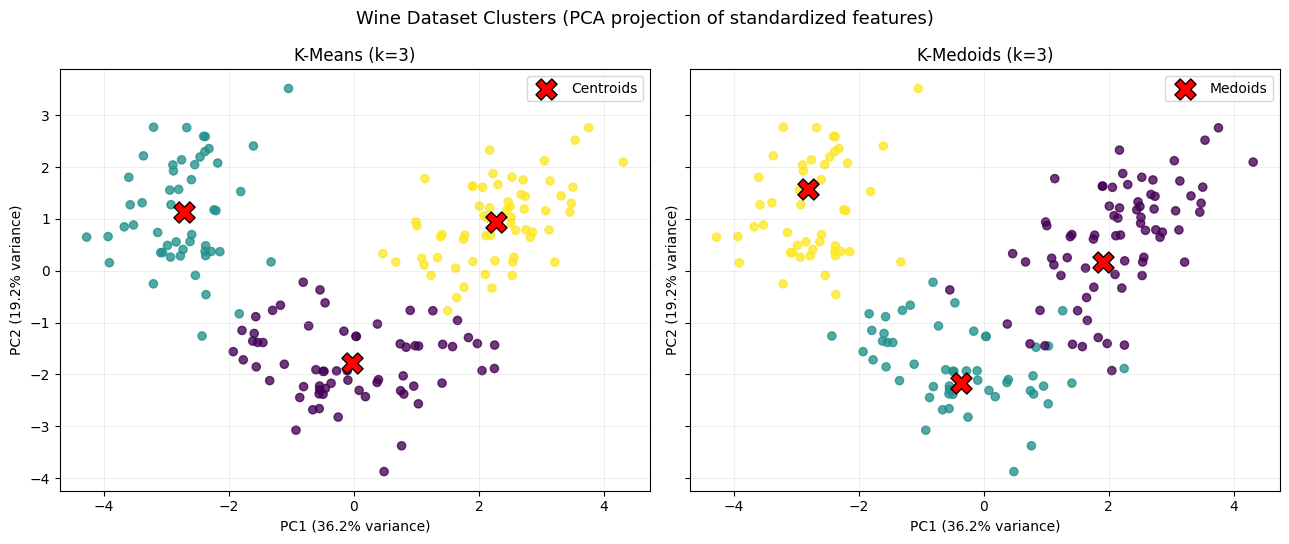

Total variance shown by first two PCs: 55.4%


In [6]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
centers_2d = pca.transform(kmeans.cluster_centers_)
medoids_2d = pca.transform(medoids)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, labels, reps, title, representative in [
    (axes[0], km_labels, centers_2d, "K-Means (k=3)", "Centroids"),
    (axes[1], med_labels, medoids_2d, "K-Medoids (k=3)", "Medoids"),
]:
    scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="viridis", s=35, alpha=0.78)
    ax.scatter(reps[:, 0], reps[:, 1], marker="X", c="red", s=230,
               edgecolors="black", linewidths=1, label=representative, zorder=5)
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend(loc="best")
    ax.grid(alpha=0.2)
fig.suptitle("Wine Dataset Clusters (PCA projection of standardized features)", fontsize=13)
fig.tight_layout()
fig.savefig(PLOT_DIR / "clustering_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Total variance shown by first two PCs: {pca.explained_variance_ratio_.sum():.1%}")

### Optional: Compare algorithms with actual class labels

The additional plot below is not used to fit or tune either model. It shows the same PCA projection colored by known wine classes to make the ARI comparison easier to interpret.

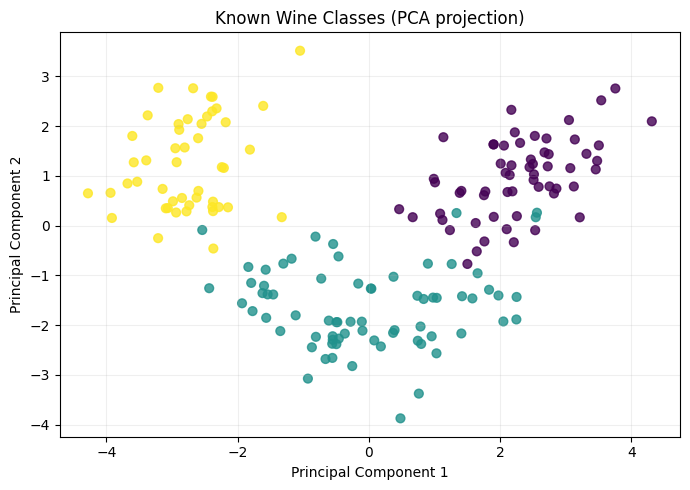

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="viridis", s=40, alpha=0.8)
ax.set(title="Known Wine Classes (PCA projection)",
       xlabel="Principal Component 1", ylabel="Principal Component 2")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(PLOT_DIR / "actual_wine_classes.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Results and discussion

The following interpretation is generated using the actual measured metrics rather than assuming one algorithm always wins.

In [8]:
sil_winner = "K-Means" if km_sil > med_sil else "K-Medoids" if med_sil > km_sil else "Neither (tie)"
ari_winner = "K-Means" if km_ari > med_ari else "K-Medoids" if med_ari > km_ari else "Neither (tie)"
print(f"1. Better-defined clusters: {sil_winner} had the higher Silhouette Score "
      f"({max(km_sil, med_sil):.4f} vs. {min(km_sil, med_sil):.4f}).")
print(f"2. Better match to the real wine types: {ari_winner} had the higher ARI "
      f"({max(km_ari, med_ari):.4f} vs. {min(km_ari, med_ari):.4f}).")
print("3. Plot interpretation: Both plots use the same PCA axes. Cluster regions can differ "
      "because K-Means uses average-based centroids while K-Medoids uses observed samples as medoids.")
print("4. When to choose: K-Means is typically faster for larger datasets and works well "
      "with compact, roughly spherical groups. K-Medoids may be a better choice when outliers "
      "are a concern or an actual representative record is needed.")
print("5. Limitation: The two PCA components are just a projection; all scores were "
      "computed in 13-dimensional standardized space. Initialization and distance choice "
      "can change outcomes, and forcing three clusters assumes that three is appropriate.")

1. Better-defined clusters: K-Means had the higher Silhouette Score (0.2849 vs. 0.2676).
2. Better match to the real wine types: K-Means had the higher ARI (0.8975 vs. 0.7411).
3. Plot interpretation: Both plots use the same PCA axes. Cluster regions can differ because K-Means uses average-based centroids while K-Medoids uses observed samples as medoids.
4. When to choose: K-Means is typically faster for larger datasets and works well with compact, roughly spherical groups. K-Medoids may be a better choice when outliers are a concern or an actual representative record is needed.
5. Limitation: The two PCA components are just a projection; all scores were computed in 13-dimensional standardized space. Initialization and distance choice can change outcomes, and forcing three clusters assumes that three is appropriate.


## 7. Conclusion

This lab demonstrated how distance-based clustering can group unlabeled data and how cluster quality can be measured from two different perspectives. The Silhouette Score checks separation without class labels, while the ARI measures agreement with the dataset's known categories. Using z-score standardization made the 13 chemical features more comparable. K-Means summarizes clusters with numerical averages, while K-Medoids chooses existing wines as representatives. The results show why algorithm selection should be supported by metrics and visual inspection rather than assuming either method is universally best.

**Implementation note:** The K-Medoids section uses a pure NumPy/scikit-learn-compatible PAM swap implementation, avoiding a dependency on `scikit-learn-extra`.